# Model Evaluation

This notebook evaluates the final classification and regression models developed for brain tumor analysis.

The classification task predicts the tumor type:
- Glioma
- Meningioma
- Pituitary tumor

The regression task predicts tumor area using extracted image features.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# 1. Classification Model Evaluation

The classification models were evaluated using validation and test performance.

The target classes are:
- Glioma
- Meningioma
- Pituitary tumor

In [3]:
# Classification model comparison

classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "SVM",
        "Gaussian Naive Bayes"
    ],
    "Validation Accuracy": [
        0.6505,
        0.6474,
        0.6413,
        0.6383,
        0.6049
    ]
})

classification_results["Accuracy (%)"] = (
    classification_results["Validation Accuracy"] * 100
).round(2)

classification_results = classification_results.sort_values(
    "Validation Accuracy",
    ascending=False
).reset_index(drop=True)

display(classification_results)

,Model,Validation Accuracy,Accuracy (%)
0,Logistic Regression,0.6505,65.05
1,KNN,0.6474,64.74
2,Decision Tree,0.6413,64.13
3,SVM,0.6383,63.83
4,Gaussian Naive Bayes,0.6049,60.49


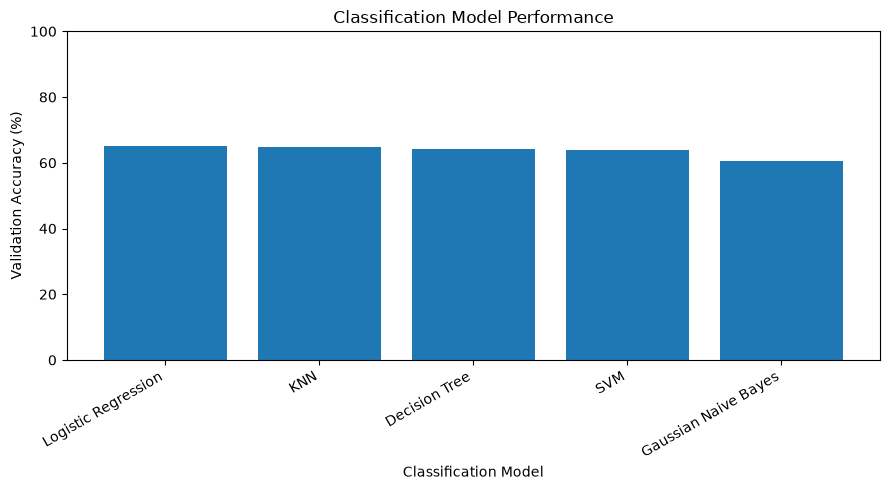

In [4]:
# Classification model comparison chart

plt.figure(figsize=(9, 5))

plt.bar(
    classification_results["Model"],
    classification_results["Accuracy (%)"]
)

plt.xlabel("Classification Model")
plt.ylabel("Validation Accuracy (%)")
plt.title("Classification Model Performance")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [5]:
# 5-Fold Cross-Validation for the Two Best Classification Models

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

# 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# --------------------------------------------------
# 1. Logistic Regression
# --------------------------------------------------

logistic_cv_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_cv_scores = cross_val_score(
    logistic_cv_model,
    X_train_scaled,
    y_train,
    cv=kf,
    scoring="accuracy"
)

# --------------------------------------------------
# 2. KNN
# --------------------------------------------------

knn_cv_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_cv_scores = cross_val_score(
    knn_cv_model,
    X_train_scaled,
    y_train,
    cv=kf,
    scoring="accuracy"
)

# --------------------------------------------------
# Display results
# --------------------------------------------------

classification_cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN"
    ],
    "Fold 1 Accuracy": [
        logistic_cv_scores[0],
        knn_cv_scores[0]
    ],
    "Fold 2 Accuracy": [
        logistic_cv_scores[1],
        knn_cv_scores[1]
    ],
    "Fold 3 Accuracy": [
        logistic_cv_scores[2],
        knn_cv_scores[2]
    ],
    "Fold 4 Accuracy": [
        logistic_cv_scores[3],
        knn_cv_scores[3]
    ],
    "Fold 5 Accuracy": [
        logistic_cv_scores[4],
        knn_cv_scores[4]
    ],
    "Mean CV Accuracy": [
        logistic_cv_scores.mean(),
        knn_cv_scores.mean()
    ]
})

print("5-Fold Cross-Validation Results for Classification:")

display(
    classification_cv_results.round(4)
)

NameError: name 'X_train_scaled' is not defined

In [6]:
# Load final Logistic Regression test predictions

prediction_path = r"C:\ML PROJECT\generated_data\logistic_test_predictions.csv"

classification_test_results = pd.read_csv(
    prediction_path
)

print("Test predictions loaded successfully!")
print("Shape:", classification_test_results.shape)

display(classification_test_results.head())

Test predictions loaded successfully!
Shape: (329, 2)


,Actual,Predicted
0,Glioma,Meningioma
1,Pituitary tumor,Pituitary tumor
2,Pituitary tumor,Pituitary tumor
3,Pituitary tumor,Meningioma
4,Meningioma,Meningioma


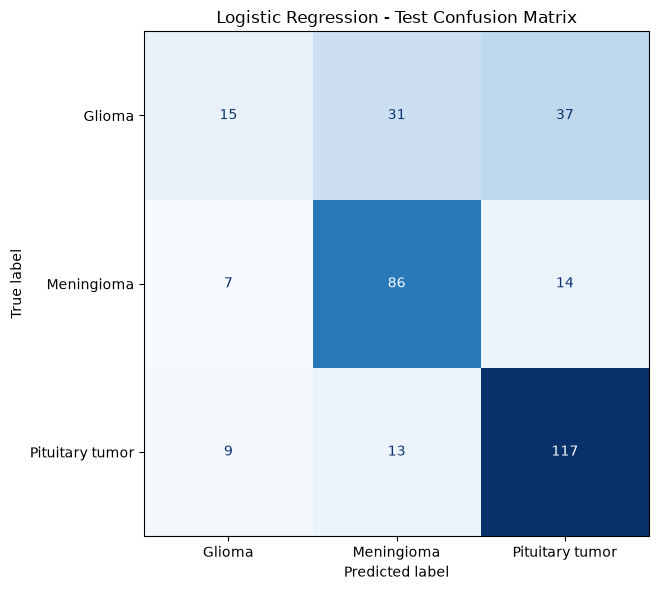

In [7]:
# Logistic Regression Confusion Matrix

cm_lr = confusion_matrix(
    classification_test_results["Actual"],
    classification_test_results["Predicted"],
    labels=[
        "Glioma",
        "Meningioma",
        "Pituitary tumor"
    ]
)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=[
        "Glioma",
        "Meningioma",
        "Pituitary tumor"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp_lr.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title("Logistic Regression - Test Confusion Matrix")

plt.tight_layout()
plt.show()

In [8]:
# Logistic Regression Test Classification Report

lr_accuracy = accuracy_score(
    classification_test_results["Actual"],
    classification_test_results["Predicted"]
)

lr_report = classification_report(
    classification_test_results["Actual"],
    classification_test_results["Predicted"]
)

print("Logistic Regression Test Accuracy:",
      round(lr_accuracy, 4))

print("\nLogistic Regression Test Classification Report:")
print(lr_report)

Logistic Regression Test Accuracy: 0.6626

Logistic Regression Test Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.48      0.18      0.26        83
     Meningioma       0.66      0.80      0.73       107
Pituitary tumor       0.70      0.84      0.76       139

       accuracy                           0.66       329
      macro avg       0.61      0.61      0.58       329
   weighted avg       0.63      0.66      0.62       329



# Classification Evaluation Summary

Logistic Regression achieved a test accuracy of **66.26%** on the brain tumor classification task.

The model performed best on **Pituitary tumor**, with a recall of **84%** and an F1-score of **76%**. It also performed reasonably well on **Meningioma**, achieving a recall of **80%**.

However, the model showed weaker performance for **Glioma**, with a recall of only **18%**. A considerable number of Glioma samples were classified as Meningioma or Pituitary tumor, as observed in the confusion matrix.

Overall, the model provides moderate classification performance, but the low Glioma recall indicates that further improvement would be required for reliable tumor-type classification.

# 2. Regression Model Evaluation

The regression task predicts the tumor area from the extracted image features.

The final selected model is **Polynomial Regression with degree 3**, which was selected after comparing multiple regression models and performing hyperparameter tuning.

In [9]:
# Load the final Polynomial Regression model

import joblib

model_path = r"C:\ML PROJECT\models\final_polynomial_regression_model.pkl"

final_poly_model = joblib.load(model_path)

print("Final Polynomial Regression model loaded successfully!")
print("Model type:", type(final_poly_model))

Final Polynomial Regression model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [10]:
# Load final Polynomial Regression test predictions

regression_prediction_path = r"C:\ML PROJECT\generated_data\polynomial_test_predictions.csv"

regression_test_results = pd.read_csv(
    regression_prediction_path
)

print("Regression test predictions loaded successfully!")
print("Shape:", regression_test_results.shape)

display(regression_test_results.head())

Regression test predictions loaded successfully!
Shape: (329, 2)


,Actual,Predicted
0,659,700.045650
1,3705,6187.566224
2,786,755.045620
3,2650,2376.571749
4,3028,3001.016129


In [11]:
# Final Polynomial Regression test evaluation

actual_regression = regression_test_results["Actual"]
predicted_regression = regression_test_results["Predicted"]

final_r2 = r2_score(
    actual_regression,
    predicted_regression
)

final_rmse = np.sqrt(
    mean_squared_error(
        actual_regression,
        predicted_regression
    )
)

final_mae = mean_absolute_error(
    actual_regression,
    predicted_regression
)

print("Final Polynomial Regression Test Results:")
print(f"R²: {final_r2:.4f}")
print(f"RMSE: {final_rmse:.2f}")
print(f"MAE: {final_mae:.2f}")

Final Polynomial Regression Test Results:
R²: 0.9395
RMSE: 826.77
MAE: 491.05


### Actual vs Predicted Tumor Area

The following plot compares the actual tumor area values with the values predicted by the final Polynomial Regression model.

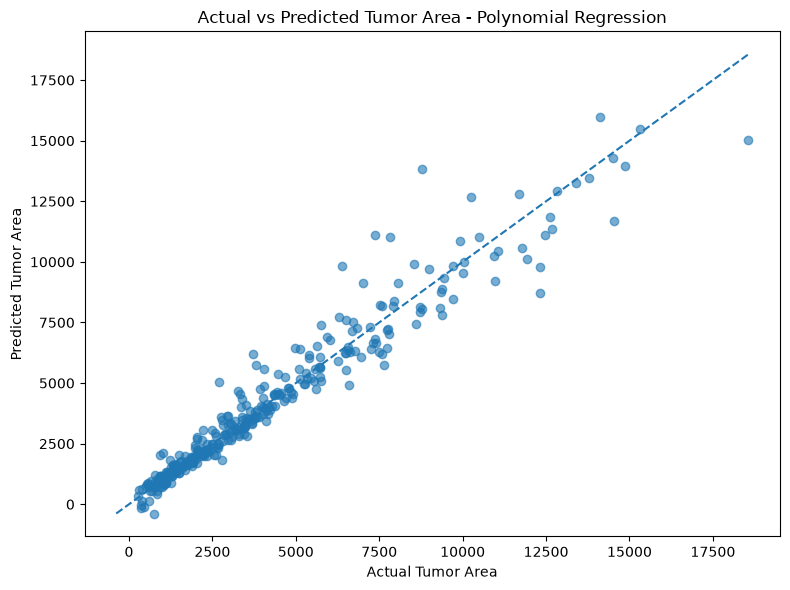

In [12]:
# Actual vs Predicted Tumor Area

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_regression,
    predicted_regression,
    alpha=0.6
)

# Perfect prediction line
min_value = min(
    actual_regression.min(),
    predicted_regression.min()
)

max_value = max(
    actual_regression.max(),
    predicted_regression.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Tumor Area")
plt.ylabel("Predicted Tumor Area")
plt.title("Actual vs Predicted Tumor Area - Polynomial Regression")

plt.tight_layout()
plt.show()

### Residual Analysis

Residuals are calculated as the difference between the actual and predicted tumor area values.

A residual close to zero indicates an accurate prediction, while larger positive or negative residuals indicate larger prediction errors.

Residual Analysis:
Mean Residual: -9.89
Residual Standard Deviation: 827.97
Minimum Residual: -5051.26
Maximum Residual: 3597.35


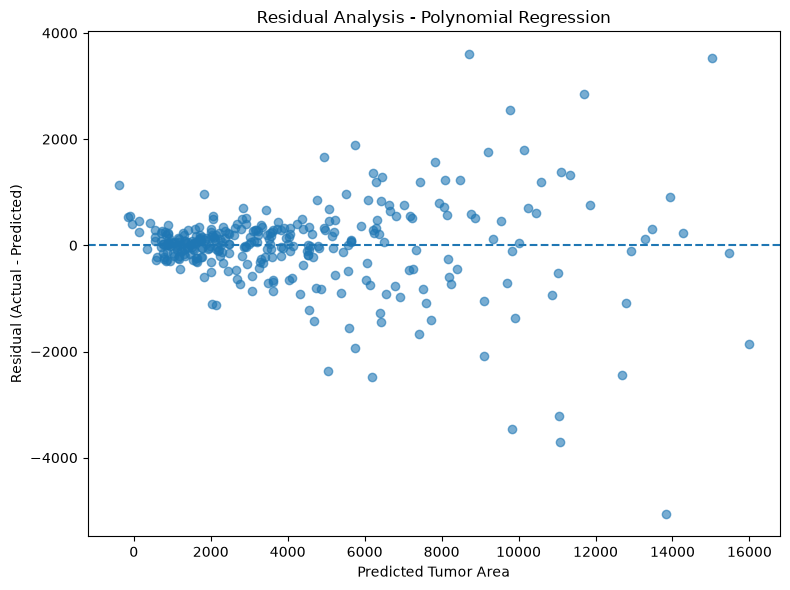

In [13]:
# Residual Analysis

residuals = actual_regression - predicted_regression

print("Residual Analysis:")
print(f"Mean Residual: {residuals.mean():.2f}")
print(f"Residual Standard Deviation: {residuals.std():.2f}")
print(f"Minimum Residual: {residuals.min():.2f}")
print(f"Maximum Residual: {residuals.max():.2f}")

plt.figure(figsize=(8, 6))

plt.scatter(
    predicted_regression,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Tumor Area")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis - Polynomial Regression")

plt.tight_layout()
plt.show()

## Regression Feature Importance

Feature importance is analyzed using the Random Forest Regressor to identify which extracted tumor features contribute most to tumor area prediction.

In [14]:
# Load regression feature dataset

data_path = r"C:\ML PROJECT\generated_data\segmentation_features.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (2192, 11)

Columns:
['image_name', 'tumor_type', 'tumor_area', 'tumor_percentage', 'tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']


In [15]:
# Prepare regression data

from sklearn.model_selection import train_test_split

regression_features = [
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity"
]

X_reg = df[regression_features]
y_reg = df["tumor_area"]

# First split: 70% training, 30% temporary
X_reg_train, X_reg_temp, y_reg_train, y_reg_temp = train_test_split(
    X_reg,
    y_reg,
    test_size=0.30,
    random_state=42
)

# Second split: divide remaining 30% equally into validation and test
X_reg_val, X_reg_test, y_reg_val, y_reg_test = train_test_split(
    X_reg_temp,
    y_reg_temp,
    test_size=0.50,
    random_state=42
)

print("Regression data split completed!")

print("\nTraining shape:", X_reg_train.shape)
print("Validation shape:", X_reg_val.shape)
print("Test shape:", X_reg_test.shape)

Regression data split completed!

Training shape: (1534, 7)
Validation shape: (329, 7)
Test shape: (329, 7)


In [16]:
# Scale regression features

from sklearn.preprocessing import StandardScaler

reg_scaler = StandardScaler()

# Fit ONLY on training data
X_reg_train_scaled = reg_scaler.fit_transform(X_reg_train)

# Transform validation and test data
X_reg_val_scaled = reg_scaler.transform(X_reg_val)
X_reg_test_scaled = reg_scaler.transform(X_reg_test)

print("Regression feature scaling completed!")

print("\nTraining scaled shape:", X_reg_train_scaled.shape)
print("Validation scaled shape:", X_reg_val_scaled.shape)
print("Test scaled shape:", X_reg_test_scaled.shape)

Regression feature scaling completed!

Training scaled shape: (1534, 7)
Validation scaled shape: (329, 7)
Test scaled shape: (329, 7)


In [17]:
# Compare all 10 regression models on the held-out test set

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd


# --------------------------------------------------
# Define the 10 regression models
# --------------------------------------------------

regression_models = {

    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Lasso Regression": Lasso(
        alpha=1.0,
        max_iter=10000
    ),

    "ElasticNet Regression": ElasticNet(
        alpha=1.0,
        l1_ratio=0.5,
        max_iter=10000
    ),

    "Decision Tree Regressor": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "SVR": SVR(
        kernel="rbf",
        C=100,
        epsilon=0.1
    ),

    "KNN Regressor": KNeighborsRegressor(
        n_neighbors=5
    )
}


# --------------------------------------------------
# Evaluate standard regression models
# --------------------------------------------------

test_results = []

for model_name, model in regression_models.items():

    model.fit(
        X_reg_train_scaled,
        y_reg_train
    )

    predictions = model.predict(
        X_reg_test_scaled
    )

    r2 = r2_score(
        y_reg_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_reg_test,
            predictions
        )
    )

    mae = mean_absolute_error(
        y_reg_test,
        predictions
    )

    test_results.append({
        "Model": model_name,
        "R²": r2,
        "RMSE": rmse,
        "MAE": mae
    })


# --------------------------------------------------
# Polynomial Regression - Degree 2 baseline
# --------------------------------------------------

poly_features = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly_features.fit_transform(
    X_reg_train_scaled
)

X_test_poly = poly_features.transform(
    X_reg_test_scaled
)

poly_model = LinearRegression()

poly_model.fit(
    X_train_poly,
    y_reg_train
)

poly_predictions = poly_model.predict(
    X_test_poly
)

test_results.append({
    "Model": "Polynomial Regression",
    "R²": r2_score(
        y_reg_test,
        poly_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_reg_test,
            poly_predictions
        )
    ),
    "MAE": mean_absolute_error(
        y_reg_test,
        poly_predictions
    )
})


# --------------------------------------------------
# Create final comparison table
# --------------------------------------------------

regression_test_comparison = pd.DataFrame(
    test_results
)

regression_test_comparison = (
    regression_test_comparison
    .sort_values(
        by="R²",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Regression Model Comparison on Held-Out Test Set:")

display(
    regression_test_comparison.round(4)
)

Regression Model Comparison on Held-Out Test Set:


,Model,R²,RMSE,MAE
0,Gradient Boosting Regressor,0.9436,798.0817,473.0471
1,Polynomial Regression,0.9418,810.9453,509.4726
2,Random Forest Regressor,0.9381,836.0042,478.4498
3,KNN Regressor,0.9309,883.3956,594.8669
4,Linear Regression,0.9229,932.9473,647.7204
5,Ridge Regression,0.9229,933.2580,647.6691
6,Lasso Regression,0.9228,933.8718,647.9185
7,Decision Tree Regressor,0.8711,1206.6198,671.1763
8,ElasticNet Regression,0.8661,1229.5609,838.6887
9,SVR,0.8132,1452.4051,722.2051


In [18]:
# 5-Fold Cross-Validation for the Two Best Regression Models

from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# --------------------------------------------------
# 1. Gradient Boosting Regressor
# --------------------------------------------------

gb_cv_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_cv_scores = cross_val_score(
    gb_cv_model,
    X_reg_train_scaled,
    y_reg_train,
    cv=kf,
    scoring="r2"
)

# --------------------------------------------------
# 2. Polynomial Regression
# --------------------------------------------------

poly_cv_model = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(
            degree=3,
            include_bias=False
        )
    ),
    (
        "linear_regression",
        LinearRegression()
    )
])

poly_cv_scores = cross_val_score(
    poly_cv_model,
    X_reg_train_scaled,
    y_reg_train,
    cv=kf,
    scoring="r2"
)

# --------------------------------------------------
# Display results
# --------------------------------------------------

cv_results = pd.DataFrame({
    "Model": [
        "Gradient Boosting Regressor",
        "Polynomial Regression (Degree 3)"
    ],
    "Fold 1 R²": [
        gb_cv_scores[0],
        poly_cv_scores[0]
    ],
    "Fold 2 R²": [
        gb_cv_scores[1],
        poly_cv_scores[1]
    ],
    "Fold 3 R²": [
        gb_cv_scores[2],
        poly_cv_scores[2]
    ],
    "Fold 4 R²": [
        gb_cv_scores[3],
        poly_cv_scores[3]
    ],
    "Fold 5 R²": [
        gb_cv_scores[4],
        poly_cv_scores[4]
    ],
    "Mean CV R²": [
        gb_cv_scores.mean(),
        poly_cv_scores.mean()
    ]
})

print("5-Fold Cross-Validation Results:")
display(cv_results.round(4))

5-Fold Cross-Validation Results:


,Model,Fold 1 R²,Fold 2 R²,Fold 3 R²,Fold 4 R²,Fold 5 R²,Mean CV R²
0,Gradient Boosting Regressor,0.9413,0.9518,0.9546,0.9499,0.9530,0.9501
1,Polynomial Regression (Degree 3),0.9377,0.9519,0.9568,0.7733,0.9456,0.9130


In [20]:
# Train Random Forest Regressor for feature importance

from sklearn.ensemble import RandomForestRegressor

rf_reg_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_reg_model.fit(
    X_reg_train_scaled,
    y_reg_train
)

print("Random Forest Regressor trained successfully!")

Random Forest Regressor trained successfully!


In [21]:
# Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": regression_features,
    "Importance": rf_reg_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
display(feature_importance)

Random Forest Feature Importance:


,Feature,Importance
1,tumor_height,0.786521
0,tumor_width,0.176499
2,aspect_ratio,0.012573
3,mean_intensity,0.007447
4,std_intensity,0.006495
6,max_intensity,0.006108
5,min_intensity,0.004356


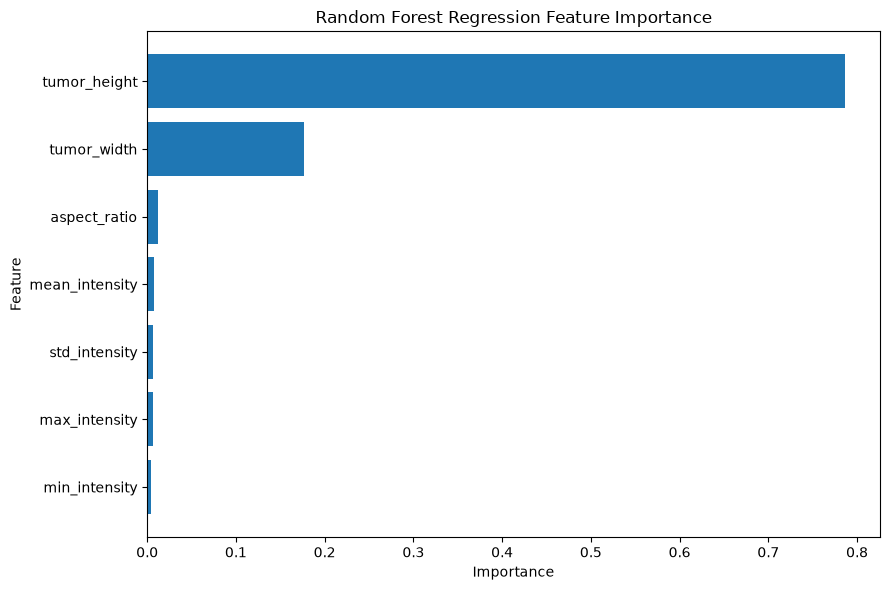

In [22]:
# Plot Random Forest feature importance

plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Regression Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Final Model Evaluation Summary

### Classification

The Logistic Regression model achieved a test accuracy of **66.26%**.

The model performed best for Pituitary tumor, followed by Meningioma. However, Glioma classification remains challenging, with a recall of **18%**.

### Regression

The final Degree-3 Polynomial Regression model achieved a test R² of **0.9395**, with an RMSE of **826.77** and MAE of **491.05**.

The Actual vs Predicted plot shows a strong agreement between actual and predicted tumor area values. The residual analysis shows that the residuals are generally centered around zero, although larger prediction errors occur for some larger tumor areas.

### Overall Conclusion

The regression component demonstrates strong predictive performance for tumor area estimation, while the classification component provides moderate performance in distinguishing among the three tumor types. Further improvement of the classification model, particularly for Glioma detection, would be beneficial.

In [24]:
# Final model performance summary

final_results = pd.DataFrame({
    "Task": [
        "Classification",
        "Regression"
    ],
    "Final Model": [
        "Logistic Regression",
        "Polynomial Regression (Degree 3)"
    ],
    "Primary Metric": [
        "Accuracy",
        "R²"
    ],
    "Test Score": [
        0.6626,
        0.9395
    ]
})

display(final_results)

,Task,Final Model,Primary Metric,Test Score
0,Classification,Logistic Regression,Accuracy,0.6626
1,Regression,Polynomial Regression (Degree 3),R²,0.9395
